# Phase 5: Independent auditor, GDPR re-identification tests, and the held-out test set

**Goal:** prove the result with numbers a reviewer can trust.

1. **Independent auditor.** A separate module (`fpdeid/auditor.py`) that does *not* use any code of the cleaner.
   It rebuilds each patient's identity from the **original** files and searches every **output** file for it
   (all header values, sequences, private tags, readable bytes, and its own OCR of the pixels).
   It is tested with **planted leaks** (we put real identifiers back into copies of clean files).
   In the pipeline it closes the loop: every header hit is removed and logged.
2. **GDPR re-identification tests** on what is left: singling out (k-anonymity), linkability (top-1 / top-5)
   and inference, for the **pseudonymised** output (our normal output, the key is kept by the hospital) and an
   **anonymised** release (no key, generalised and suppressed quasi-identifiers).
3. **The MIDI-B test set, once** (322 patients, 29,660 files), with the rules frozen before the run.
4. **Privacy vs utility** plot, the **ablation table** of all phases, and the **error analysis** of the test run.

The pipeline itself runs with `scripts/run_split.py` (headers → pixels → auditor → official scorer); this
notebook reads its outputs. If they are missing, the first cells run it.

Pass criteria (docs/PLAN.md): test score ≥ 99%, all misses explained; leaks in text and pixels 0 or each listed;
auditor finds 100% of planted leaks; auditor false alarms reported per 10,000 elements; singling out,
linkability (vs random) and inference (vs majority) reported; research-field retention and DICOM validity
on the test set 100%.

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

import gzip
import json
import pickle
import random
import re
import shutil
import subprocess
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pydicom

from fpdeid import paths
from fpdeid import pipeline
from fpdeid import scoring
from fpdeid import auditor
from fpdeid import plant_leaks
from fpdeid import reid_attack
from fpdeid import checks
from fpdeid import validity

pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

phase_results = os.path.join(paths.RESULTS, "phase5")
os.makedirs(phase_results, exist_ok=True)
scorer_runs = os.path.join(paths.DERIVED, "scorer_runs")


def output_folder(split):
    return os.path.join(paths.OUTPUTS, "phase5_" + split)


def scorer_db(split):
    return os.path.join(scorer_runs, "phase5_" + split, "validation_results.db")


def ensure_run(split):
    """Run scripts/run_split.py for this split only if its outputs or its score are missing."""
    if os.path.exists(os.path.join(output_folder(split), "auditor_hits.json")) and os.path.exists(scorer_db(split)):
        print(split, ": outputs and score found, not run again")
        return
    command = [sys.executable, os.path.join(paths.PROJECT, "scripts", "run_split.py"), split]
    subprocess.run(command, check=True)


def cached_pixel_audit(name, jobs):
    """The auditor's OCR is slow (GPU), so its result is saved once and reused when the notebook runs again."""
    cache_path = os.path.join(paths.DERIVED, "phase5_auditor_ocr_" + name + ".pkl")
    if os.path.exists(cache_path):
        with open(cache_path, "rb") as f:
            saved = pickle.load(f)
        if saved["files"] == [job[1] for job in jobs]:
            print("reused saved OCR results of the auditor for", name)
            return saved["hits"], saved["texts"]
    hits, texts = auditor.audit_pixel_files(jobs)
    with open(cache_path, "wb") as f:
        pickle.dump({"files": [job[1] for job in jobs], "hits": hits, "texts": texts}, f)
    return hits, texts


def load_summary(split):
    with open(os.path.join(output_folder(split), "summary.json")) as f:
        return json.load(f)

## 1. The frozen pipeline on the validation set (same rules as Phase 4 + the auditor step)

In [2]:
ensure_run("validation")
validation_summary = load_summary("validation")
validation_results = scoring.add_categories(scoring.load_results(scorer_db("validation")))
validation_score = scoring.summarise(validation_results)
validation_score.update(scoring.privacy_utility(validation_results))

phase4 = pd.read_csv(os.path.join(paths.RESULTS, "phase4", "scores_vs_phase3.csv"), index_col=0)
compare = phase4[["Phase 4"]].copy()
compare["Phase 5 (validation)"] = pd.Series(validation_score)
compare

validation : outputs and score found, not run again


,Phase 4,Phase 5 (validation)
weighted_score_%,99.831,99.831
hipaa_accuracy_%,99.996,99.996
dicom_accuracy_%,100.000,100.000
tcia_accuracy_%,98.342,98.342
privacy_failed,5177.000,5177.000
utility_failed,55004.000,55004.000
consistency_failed,0.000,0.000


## 2. The independent auditor

### 2.1 Header scan of every validation output file

In [3]:
validation_jobs = pipeline.auditor_jobs("validation", output_folder("validation"))
start = time.time()
validation_hits, validation_elements = auditor.audit_headers(validation_jobs, workers=16)
audit_seconds = time.time() - start
with open(os.path.join(output_folder("validation"), "auditor_hits.json")) as f:
    hits_before_fix = json.load(f)
print("files:", sum(len(job[1]) for job in validation_jobs), "| elements read:", validation_elements,
      "| seconds:", round(audit_seconds, 1))
print("hits found by the auditor in the pipeline (before its fix):", len(hits_before_fix),
      "| hits now (after the fix):", len(validation_hits))
print("hits per 10,000 elements:", round(10000 * len(hits_before_fix) / validation_elements, 3))

files: 23921 | elements read: 4963487 | seconds: 33.2
hits found by the auditor in the pipeline (before its fix): 0 | hits now (after the fix): 0
hits per 10,000 elements: 0.0


### 2.2 Pixel scan with the auditor's own OCR
Every X-ray / mammography / ultrasound image, and the middle slice of every CT, MR and PET series.

In [4]:
def pixel_scan_jobs(split, jobs):
    file_table = pipeline.load_file_table(split)
    modality_of = dict(zip(file_table["path"], file_table["modality"]))
    series_of = dict(zip(file_table["path"], file_table["series_uid"]))
    scan = []
    for original_paths, output_paths in jobs:
        by_series = {}
        for original, output in zip(original_paths, output_paths):
            modality = modality_of[original]
            if modality in ["SR", "PR", "KO", "RTSTRUCT", "SEG"]:
                continue
            if modality in ["CT", "MR", "PT", "NM"]:
                by_series.setdefault(series_of[original], []).append(output)
            else:
                scan.append((original_paths, output))
        for series, outputs in by_series.items():
            outputs = sorted(outputs)
            scan.append((original_paths, outputs[len(outputs) // 2]))
    return scan


validation_scan = pixel_scan_jobs("validation", validation_jobs)
start = time.time()
validation_pixel_hits, validation_ocr = cached_pixel_audit("validation", validation_scan)
pixel_seconds = time.time() - start
print("images read by the auditor's OCR:", len(validation_scan), "| seconds:", round(pixel_seconds))
print("pixel hits:", len(validation_pixel_hits))
pd.DataFrame(validation_pixel_hits)

reused saved OCR results of the auditor for validation
images read by the auditor's OCR: 415 | seconds: 0
pixel hits: 0


""


### 2.3 Planted leaks: does the auditor find identifiers that we put back on purpose?
100 copies of clean output files get one real identifier of their own patient each (name in another order,
surname, ID, accession number, birth or study date in 5 written forms, doctor, hospital, an original UID),
in 6 different places (comments, appended to a description, private text tag, private bytes, inside a
sequence, patient comments). 20 more copies get the patient's name or ID **written into the pixels**.

In [5]:
random.seed(5)
planted_folder = os.path.join(paths.DERIVED, "planted_leaks")
shutil.rmtree(planted_folder, ignore_errors=True)

file_table = pipeline.load_file_table("validation")
patient_of = dict(zip(file_table["path"], file_table["patient_id"]))
modality_of = dict(zip(file_table["path"], file_table["modality"]))
originals_of_patient = {}
pairs = []
for original_paths, output_paths in validation_jobs:
    originals_of_patient[patient_of[original_paths[0]]] = original_paths
    for original, output in zip(original_paths, output_paths):
        pairs.append((original, output))

plants = []
header_jobs = []
for i, (original, output) in enumerate(random.sample(pairs, 100)):
    copy_path = os.path.join(planted_folder, "header", str(i).zfill(3) + ".dcm")
    plants.append(plant_leaks.plant_header(output, original, copy_path, i))
    header_jobs.append((originals_of_patient[patient_of[original]], [copy_path]))

image_pairs = [(o, out) for o, out in pairs if modality_of[o] in ["CR", "DX", "MG", "US"]]
random.shuffle(image_pairs)
pixel_jobs = []
for original, output in image_pairs:
    if len(pixel_jobs) == 20:
        break
    copy_path = os.path.join(planted_folder, "pixels", str(len(pixel_jobs)).zfill(3) + ".dcm")
    try:
        plants.append(plant_leaks.plant_pixels(output, original, copy_path, len(pixel_jobs)))
    except Exception as problem:
        print("skipped (pixels not writable):", modality_of[original], str(problem)[:80])
        continue
    pixel_jobs.append((originals_of_patient[patient_of[original]], copy_path))

planted_header_hits, planted_elements = auditor.audit_headers(header_jobs, workers=16)
planted_pixel_hits, planted_ocr = cached_pixel_audit("planted", pixel_jobs)
found_files = set(hit["file"] for hit in planted_header_hits + planted_pixel_hits)

plant_table = pd.DataFrame(plants)
plant_table["found"] = plant_table["copy"].isin(found_files)
plant_recall = plant_table.groupby(["where", "kind"])["found"].agg(["count", "sum"])
plant_recall = plant_recall.rename(columns={"count": "planted", "sum": "found"})
plant_recall.loc[("all", ""), :] = [len(plant_table), int(plant_table["found"].sum())]
plant_recall.to_csv(os.path.join(phase_results, "auditor_planted_leaks.csv"))
plant_recall

skipped (pixels not writable): US Missing required element: (0028,0006) 'Planar Configuration'


planted  found
where  kind                            
header date                 23.0   23.0
       id                   20.0   20.0
       name                 35.0   35.0
       place or contact      9.0    9.0
       uid                  13.0   13.0
pixels id                   10.0   10.0
       name                 10.0   10.0
all                        120.0  120.0

In [6]:
by_place = plant_table.groupby("place")["found"].agg(["count", "sum"]).rename(columns={"count": "planted",
                                                                                      "sum": "found"})
by_place

,planted,found
place,,
ImageComments,17,17
PatientComments,11,11
SeriesDescription (appended),15,15
UID inside a sequence,13,13
inside a sequence,16,16
pixels (corner 0),5,5
pixels (corner 1),5,5
pixels (corner 2),5,5
pixels (corner 3),5,5


In [7]:
missed_plants = plant_table[~plant_table["found"]]
print("missed planted leaks:", len(missed_plants))
for _, plant in missed_plants.iterrows():
    print(plant["where"], "|", plant["kind"], "|", plant["place"], "| OCR read:", planted_ocr.get(plant["copy"], "")[:6])

missed planted leaks: 0


In [8]:
# the closed loop on the planted copies: fix, then audit again
fix_log = os.path.join(planted_folder, "fixes.jsonl")
fixed = auditor.fix_header_hits(planted_header_hits, fix_log)
hits_after_fix, n = auditor.audit_headers(header_jobs, workers=16)
readable = 0
for job in header_jobs:
    pydicom.dcmread(job[1][0])
    readable = readable + 1
print("planted files fixed:", fixed, "| hits after the fix:", len(hits_after_fix), "| still readable:", readable)

planted files fixed: 100 | hits after the fix: 0 | still readable: 100


### 2.4 Auditor vs. the official scorer
The scorer knows (from the answer key) which values are PHI; the auditor only knows the patient's own identity.
Which scorer leaks could the auditor see? A leak is "visible" to the auditor if the value it should have removed
contains one of the patient's identifiers.

In [9]:
def identity_by_output_patient(jobs):
    identities = {}
    for original_paths, output_paths in jobs:
        identity = auditor.identity_of_files(original_paths[:50])
        output_patient = output_paths[0].split("/")[-3]
        identities[output_patient] = auditor.build_matchers(identity)
    return identities


def leaks_seen_by_auditor(results, jobs):
    failed = scoring.failures_by_cause(results)
    leaks = failed[failed["cause"].str.startswith("LEAK")].copy()
    matchers = identity_by_output_patient(jobs)
    seen = []
    for row in leaks.to_dict("records"):
        patient = str(row["patient"]).strip("<>")
        found = []
        if patient in matchers:
            found = auditor.find_in_text(str(row["file_value"]), matchers[patient])
        seen.append(len(found) > 0)
    leaks["auditor sees it"] = seen
    return leaks


validation_leaks = leaks_seen_by_auditor(validation_results, validation_jobs)
print("scorer leaks:", len(validation_leaks), "| with an identifier of the patient's own header in the value:",
      int(validation_leaks["auditor sees it"].sum()))
validation_leaks.groupby(["tag_name", "auditor sees it"]).size().unstack(fill_value=0)

scorer leaks: 39 | with an identifier of the patient's own header in the value: 0


auditor sees it,False
tag_name,
<Image Comments>,1
<Patient Comments>,16
<Text Value>,22


## 3. GDPR re-identification tests (validation)

One row per patient. The attacker's **background knowledge** = the original hospital records of all patients
(the strongest realistic attacker: an insider, or a leak of the hospital system). A weaker **public** attacker
only knows sex, age and the year of the scan (e.g. from social media).

In [10]:
def original_patient_table(split):
    table = pipeline.load_file_table(split)
    first_files = table.groupby("series_uid")["path"].first().tolist()
    return reid_attack.patient_table(first_files)


def output_patient_table(split):
    first_files = {}
    with open(os.path.join(output_folder(split), "audit.jsonl")) as f:
        for line in f:
            record = json.loads(line)
            if record["output"] == "":
                continue
            series_folder = os.path.dirname(record["output"])
            first_files.setdefault(series_folder, record["output"])
    return reid_attack.patient_table(list(first_files.values()))


def patient_link(split):
    mapping = pd.read_csv(pipeline.SPLITS[split]["patient_map"], dtype=str)
    return dict(zip(mapping["id_new"], mapping["id_old"]))


STRONG_QIS = [c for c in reid_attack.QI_COLUMNS if c != "study_year"]
PUBLIC_QIS = ["sex", "age", "study_year"]


def reid_report(split):
    originals = original_patient_table(split)
    outputs = output_patient_table(split)
    link = patient_link(split)

    releases = {"pseudonymised (FP-DeID output)": (outputs, None)}
    generalised = reid_attack.generalise(outputs)
    releases["generalised only"] = (generalised, reid_attack.generalise)
    for k in [2, 3, 5, 10]:
        anonymised, suppressed = reid_attack.anonymise(outputs, k)
        releases["anonymised, k=" + str(k)] = (anonymised, reid_attack.generalise)

    rows = []
    for name, (release, prepare) in releases.items():
        if prepare is None:
            strong_columns = STRONG_QIS
            single_columns = reid_attack.QI_COLUMNS
        else:
            strong_columns = reid_attack.ANONYMISED_QIS
            single_columns = reid_attack.ANONYMISED_QIS
        single = reid_attack.singling_out(release, single_columns)
        strong = reid_attack.linkability(release, originals, link, strong_columns, prepare)
        public = reid_attack.linkability(release, originals, link, PUBLIC_QIS, prepare)
        row = {"release": name,
               "unique patients %": single["unique (k=1) %"], "patients with k < 5 %": single["k < 5 %"],
               "min k": single["min k"],
               "link top-1 % (insider)": strong["top-1 %"], "link top-5 % (insider)": strong["top-5 %"],
               "link top-1 % (public)": public["top-1 %"], "link top-5 % (public)": public["top-5 %"],
               "random top-1 %": strong["random top-1 %"],
               "QI information kept %": reid_attack.information_kept(originals, release, link,
                                                                      reid_attack.QI_COLUMNS)}
        rows.append(row)
    table = pd.DataFrame(rows).set_index("release")

    originals["birth_year"] = originals["birth_year"].astype(str)
    inference_pseudo = reid_attack.inference(outputs, originals, link)
    inference_pseudo.insert(0, "release", "pseudonymised")
    anonymised5, suppressed5 = reid_attack.anonymise(outputs, 5)
    inference_anon = reid_attack.inference(anonymised5, originals, link)
    inference_anon.insert(0, "release", "anonymised, k=5")
    inference_table = pd.concat([inference_pseudo, inference_anon], ignore_index=True)
    return table, inference_table, originals, outputs


validation_reid, validation_inference, validation_originals, validation_outputs = reid_report("validation")
validation_reid.to_csv(os.path.join(phase_results, "reid_validation.csv"))
validation_reid

,unique patients %,patients with k < 5 %,min k,link top-1 % (insider),link top-5 % (insider),link top-1 % (public),link top-5 % (public),random top-1 %,QI information kept %
release,,,,,,,,,
pseudonymised (FP-DeID output),99.1,100.0,1,98.6,100.0,32.5,72.5,0.46,94.7
generalised only,84.7,100.0,1,91.0,100.0,16.7,68.2,0.46,60.3
"anonymised, k=2",0.0,69.3,2,30.3,76.4,8.5,40.1,0.46,36.4
"anonymised, k=3",0.0,27.8,3,13.3,54.5,4.0,19.2,0.46,26.6
"anonymised, k=5",0.0,0.0,5,8.3,41.5,2.3,11.3,0.46,22.4
"anonymised, k=10",0.0,0.0,10,5.3,26.7,1.4,7.0,0.46,18.8


In [11]:
validation_inference.to_csv(os.path.join(phase_results, "inference_validation.csv"), index=False)
validation_inference

,release,hidden fact,attacker accuracy %,majority-guess accuracy %,patients with this fact
0,pseudonymised,study year,9.3,12.0,216
1,pseudonymised,birth year,8.3,3.2,216
2,pseudonymised,hospital,1.5,1.5,68
3,"anonymised, k=5",study year,12.0,12.0,216
4,"anonymised, k=5",birth year,3.2,3.2,216
5,"anonymised, k=5",hospital,1.5,1.5,68


In [12]:
# which quasi-identifiers make patients unique? (pseudonymised output, one field at a time)
one_field = []
for column in reid_attack.QI_COLUMNS:
    result = reid_attack.singling_out(validation_outputs, [column])
    one_field.append({"field": column, "different values": validation_outputs[column].astype(str).nunique(),
                      "unique patients %": result["unique (k=1) %"]})
pd.DataFrame(one_field).sort_values("unique patients %", ascending=False)

,field,different values,unique patients %
2,weight,161,61.6
9,study_gaps,23,10.2
6,models,50,9.7
1,age,65,5.1
3,height,52,2.8
5,manufacturers,21,2.3
7,body_parts,13,1.4
4,modalities,12,0.9
0,sex,3,0.0
8,n_studies,3,0.0


## 4. The held-out MIDI-B test set (run once, rules frozen)

In [13]:
ensure_run("test")
test_summary = load_summary("test")
with open(os.path.join(output_folder("test"), "auditor_hits.json")) as f:
    test_auditor_hits = json.load(f)
pd.Series(test_summary)

test : outputs and score found, not run again


split                                     test
files                                    29660
patients                                   322
fingerprint seconds                       19.3
header seconds                            38.0
header errors                                0
files read by OCR                          909
files skipped by series screening        28709
files with hidden text                      33
files whose pixels could not be read         0
common codes (kept)                         12
OCR seconds                             1475.9
total seconds                           2239.1
dtype: object

In [14]:
test_results = scoring.add_categories(scoring.load_results(scorer_db("test")))
test_score = scoring.summarise(test_results)
test_score.update(scoring.privacy_utility(test_results))
scores = pd.DataFrame({"validation": pd.Series(validation_score), "test": pd.Series(test_score)})
scores.to_csv(os.path.join(phase_results, "scores_validation_vs_test.csv"))
scores

,validation,test
checks,6173204.000,8035948.000
plain_accuracy_%,99.025,99.010
hipaa_checks,567859.000,697264.000
hipaa_accuracy_%,99.996,99.950
dicom_checks,1977969.000,2376692.000
dicom_accuracy_%,100.000,99.995
tcia_checks,3627376.000,4961992.000
tcia_accuracy_%,98.342,98.406
weighted_score_%,99.831,99.805
privacy_checks,717810.000,884700.000


In [15]:
test_per_action = scoring.per_action(test_results)
test_per_action.to_csv(os.path.join(phase_results, "test_per_action.csv"))
test_per_action

,checks,passed,failed,accuracy_%
action,,,,
<date_shifted>,171930,171840.0,90.0,99.948
<patid_consistent>,29660,29660.0,0.0,100.000
<pixels_hidden>,27,25.0,2.0,92.593
<pixels_retained>,29633,29624.0,9.0,99.970
<tag_retained>,1325259,1325250.0,9.0,99.999
<text_notnull>,741498,741388.0,110.0,99.985
<text_removed>,432468,418795.0,13673.0,96.838
<text_retained>,4744923,4679273.0,65650.0,98.616
<uid_changed>,280275,280275.0,0.0,100.000


In [16]:
test_results["passed"] = test_results["check_passed"].fillna(0).astype(float)
test_per_modality = test_results.groupby("modality")["passed"].agg(["count", "mean"])
test_per_modality["accuracy_%"] = (100 * test_per_modality["mean"]).round(3)
test_per_modality = test_per_modality.drop(columns="mean").rename(columns={"count": "checks"})
test_per_modality.to_csv(os.path.join(phase_results, "test_per_modality.csv"))
test_per_modality

,checks,accuracy_%
modality,,
<CR>,4306,100.000
<CT>,1287135,99.711
<DX>,10530,99.630
<MG>,21255,100.000
<MR>,1403281,98.200
<PT>,5212564,99.031
<SR>,85511,99.984
<US>,11366,100.000


### 4.1 Error analysis: every failed check of the test run, grouped by cause

In [17]:
test_failed = scoring.failures_by_cause(test_results)
cause_table = test_failed.groupby(["cause", "score_cat"]).size().unstack(fill_value=0)
cause_table["total"] = cause_table.sum(axis=1)
cause_table = cause_table.sort_values("total", ascending=False)
cause_table.to_csv(os.path.join(phase_results, "test_failures_by_cause.csv"))
cause_table

score_cat,dicom,hipaa,tcia,total
cause,,,,
private value empty in the input,0,0,43917,43917
private tag inside a private sequence: the scorer cannot read it (also fails for unchanged files),0,0,14914,14914
private value removed by TCIA's vendor knowledge base (not PHI),0,0,12842,12842
icon image removed on purpose (may show burned-in text),0,0,6097,6097
LEAK: identifier not found by fingerprint or patterns,0,256,575,831
label of a private block whose content was binary and removed,0,0,409,409
other: <text_retained>,0,0,136,136
other: <text_notnull>,110,0,0,110
over-cleaning in free text,0,0,95,95


In [18]:
test_jobs = pipeline.auditor_jobs("test", output_folder("test"))
test_leaks = leaks_seen_by_auditor(test_results, test_jobs)
leak_list = test_leaks.groupby(["tag_name", "modality", "auditor sees it"]).size().reset_index(name="checks")
leak_list.to_csv(os.path.join(phase_results, "test_leak_list.csv"), index=False)
print("test leaks:", len(test_leaks))
leak_list

test leaks: 921


,tag_name,modality,auditor sees it,checks
0,<Additional Patient History>,<CT>,False,75
1,<Additional Patient History>,<DX>,False,1
2,<Additional Patient History>,<MR>,False,555
3,<Image Comments>,<CT>,False,7
4,<Image Comments>,<MR>,False,3
5,<Patient Comments>,<DX>,False,1
6,<Referenced File ID>,<MR>,False,64
7,<Study Comments>,<CT>,False,111
8,<Text Value>,<SR>,False,14
9,<[Start time(secs) in first axial]>,<CT>,False,90


In [19]:
# examples of the leaks (synthetic data; the values stay out of git)
test_leaks[["tag_name", "file_value", "answer_value"]].drop_duplicates("file_value").head(25)

,tag_name,file_value,answer_value
733788,<Image Comments>,"<Patient Followup request for, call 7404159161>","<Patient Followup request for Dr. Wood, call 7404159161>"
939103,<Image Comments>,"<POST CONTRAST at Meyer, Moore and Coffey Community Hospital>","<POST CONTRAST at Meyer, Moore and Coffey Community Hospital>"
1165761,<Additional Patient History>,<Admitted to White Hospital>,<Admitted to White Hospital on 20180526>
3316746,<Text Value>,<RD>,<RD>
3317569,<Text Value>,<CH>,<CH>
3751902,<Additional Patient History>,"<Other specified disorders of kidney and ureter, n/a>","<Other specified disorders of kidney and ureter, n/a : James Galva..."
3784562,<Study Comments>,"<Patient Followup request for, call 0223016700>","<Patient Followup request for Dr. Obrien, call 0223016700>"
3791704,<[Start time(secs) in first axial]>,<1348576679.0>,<1348576679.0>
4246514,<Text Value>,<CW>,<CW>
5498906,<Additional Patient History>,"<Patient Followup request for, call 6438544062>","<Patient Followup request for Dr. Hines, call 6438544062>"


In [20]:
# what is left in each leaking value? (simple rules, one kind per leak)
def leak_kind(row):
    value = str(row["file_value"])
    upper = value.upper()
    if row["tag_name"] == "<Referenced File ID>":
        return "file name made of numbers (Referenced File ID)"
    if re.search(r"\d{10}\.\d", value):
        return "Unix time written as a decimal number (private start time)"
    if re.search(r"\d{10}", value):
        return "phone number written as 10 digits without separators"
    if "HOSPITAL" in upper or "CLINIC" in upper or "MEDICAL CENTER" in upper:
        return "hospital name that is not in the patient's header"
    if re.search(r"\d+ .*, [A-Z]{2} \d{5}", value):
        return "street address that is not in the patient's header"
    if re.fullmatch(r"<[A-Z]{2,3}>", value):
        return "2-3 letter initials in a structured report"
    return "other (e.g. a name not in the header, removed only partly)"


test_leaks["what is left"] = test_leaks.apply(leak_kind, axis=1)
leak_kinds = test_leaks.groupby("what is left").size().sort_values(ascending=False).reset_index(name="checks")
leak_kinds.to_csv(os.path.join(phase_results, "test_leak_kinds.csv"), index=False)
leak_kinds

,what is left,checks
0,hospital name that is not in the patient's header,497
1,phone number written as 10 digits without separators,135
2,Unix time written as a decimal number (private start time),90
3,"other (e.g. a name not in the header, removed only partly)",76
4,file name made of numbers (Referenced File ID),64
5,street address that is not in the patient's header,45
6,2-3 letter initials in a structured report,14


In [21]:
pixel_checks = test_results[test_results["action"] == "<pixels_hidden>"][["check_passed", "modality", "action_text"]]
pixel_checks.to_csv(os.path.join(phase_results, "test_pixel_checks.csv"), index=False)
print("burned-in text checks passed:", int(pixel_checks["check_passed"].fillna(0).sum()), "of", len(pixel_checks))
pixel_checks

burned-in text checks passed: 25 of 27


,check_passed,modality,action_text
1554560,1,<MG>,"<{""text"": ""EVANS REBECCA [F] 06.22.2014\nDOB: 04.25.1937"", ""top_le..."
2101279,1,<CR>,"<{""text"": ""BIRD CHRISTOPHER [M] 12.05.2016\nDOB: 11.06.1977"", ""top..."
2101512,0,<DX>,"<{""text"": ""SWU"", ""top_left"": [3048, 349], ""bottom_right"": [3167, 4..."
2101653,1,<DX>,"<{""text"": ""ONEAL DARRELL [U] 04.13.2012\nDOB: 02.19.1940"", ""top_le..."
2102311,1,<CR>,"<{""text"": ""HANCOCK KRISTI [F] 07.16.2013\nDOB: 05.31.1951"", ""top_l..."
2642123,1,<DX>,"<{""text"": ""RAY RYAN [M] 07.06.2011\nDOB: 06.03.1968"", ""top_left"": ..."
2839965,1,<MG>,"<{""text"": ""SAWYER MONIQUE [F] 05.09.2018\nDOB: 04.21.1994"", ""top_l..."
2840275,1,<CR>,"<{""text"": ""GOMEZ MATTHEW [M] 10.13.2016\nDOB: 09.27.1994"", ""top_le..."
2854500,1,<CR>,"<{""text"": ""FTA"", ""top_left"": [225, 213], ""bottom_right"": [318, 317]}>"
3043098,1,<DX>,"<{""text"": ""LACI"", ""top_left"": [1618, 130], ""bottom_right"": [1734, ..."


### 4.2 The auditor on the test set (headers in the pipeline, pixels here)

In [22]:
test_hits_now, test_elements = auditor.audit_headers(test_jobs, workers=16)
print("header hits found and fixed in the pipeline:", len(test_auditor_hits), "| hits now:", len(test_hits_now),
      "| elements read:", test_elements)
pd.DataFrame(test_auditor_hits).groupby(["kind", "tag"]).size() if len(test_auditor_hits) > 0 else None

header hits found and fixed in the pipeline: 55 | hits now: 0 | elements read: 6689686


kind       tag        
name word  (0010,2160)    55
dtype: int64

In [23]:
test_scan = pixel_scan_jobs("test", test_jobs)
test_pixel_hits, test_ocr = cached_pixel_audit("test", test_scan)
print("images read by the auditor's OCR:", len(test_scan), "| pixel hits:", len(test_pixel_hits))
pd.DataFrame(test_pixel_hits)

reused saved OCR results of the auditor for test
images read by the auditor's OCR: 482 | pixel hits: 0


""


### 4.3 Validity, utility, dates, UIDs and audit coverage on every test file

In [24]:
test_pairs = []
for original_paths, output_paths in test_jobs:
    for original, output in zip(original_paths, output_paths):
        test_pairs.append((original, output))

start = time.time()
test_valid = validity.check_pairs(test_pairs, workers=24)
test_valid_pct = 100 * (test_valid["new_errors"] == 0).mean()
print("valid files (no new dciodvfy error):", round(test_valid_pct, 3), "% of", len(test_valid), "|",
      round(time.time() - start), "s")

valid files (no new dciodvfy error): 100.0 % of 29660 | 65 s


In [25]:
# tag paths logged for each file: header audit + pixel audit + auditor fixes
audited = {}
with open(os.path.join(output_folder("test"), "audit.jsonl")) as f:
    for line in f:
        record = json.loads(line)
        audited[record["input"]] = set(change["tag"] for change in record["changes"])
output_to_input = {output: original for original, output in test_pairs}
pixel_tags = ["(0028,0004)", "(0028,0006)", "(0028,0301)"]
with open(os.path.join(output_folder("test"), "audit_pixels.jsonl")) as f:
    for line in f:
        entry = json.loads(line)
        if entry["hidden_boxes"] > 0:
            audited[entry["input"]].update(pixel_tags)
with open(os.path.join(output_folder("test"), "audit_auditor_fixes.jsonl")) as f:
    for line in f:
        entry = json.loads(line)
        audited[output_to_input[entry["file"]]].add(entry["tag"])

uid_map = pd.read_csv(paths.TEST_UID_MAP, dtype=str)
input_uids = set(uid_map["id_old"])
check_jobs = [(original, output, audited[original]) for original, output in test_pairs]
check_table = pd.DataFrame(checks.run_checks(check_jobs, input_uids, workers=16))

independent = {}
independent["audit coverage %"] = round(100 * (1 - check_table["changed_not_logged"].sum() /
                                               check_table["changed_paths"].sum()), 4)
independent["research fields kept %"] = round(100 * check_table["utility_kept"].sum() /
                                              check_table["utility_present"].sum(), 4)
independent["date intervals kept %"] = round(100 * check_table["date_pairs_same"].sum() /
                                             max(1, check_table["date_pairs"].sum()), 4)
independent["original UIDs left"] = int(check_table["original_uids_left"].sum())
independent["invalid UIDs"] = int(check_table["invalid_uids"].sum())
pd.Series(independent)

audit coverage %          100.0
research fields kept %    100.0
date intervals kept %     100.0
original UIDs left          0.0
invalid UIDs                0.0
dtype: float64

In [26]:
lost = check_table["utility_lost"].str.split(",").explode()
lost = lost[lost != ""]
print("research fields lost:", lost.value_counts().head(10).to_dict())
print("changes not in the audit log (examples):",
      check_table[check_table["changed_not_logged"] > 0]["not_logged_examples"].head(5).tolist())

research fields lost: {}
changes not in the audit log (examples): []


### 4.4 Re-identification tests on the test set

In [27]:
test_reid, test_inference, test_originals, test_outputs = reid_report("test")
test_reid.to_csv(os.path.join(phase_results, "reid_test.csv"))
test_reid

,unique patients %,patients with k < 5 %,min k,link top-1 % (insider),link top-5 % (insider),link top-1 % (public),link top-5 % (public),random top-1 %,QI information kept %
release,,,,,,,,,
pseudonymised (FP-DeID output),99.4,100.0,1,98.4,100.0,28.4,70.8,0.31,94.7
generalised only,81.1,100.0,1,88.5,100.0,12.7,51.9,0.31,60.2
"anonymised, k=2",0.0,73.6,2,31.2,79.1,7.3,32.8,0.31,38.9
"anonymised, k=3",0.0,42.5,3,16.3,62.4,4.5,22.1,0.31,30.6
"anonymised, k=5",0.0,0.0,5,7.3,36.7,1.7,8.5,0.31,23.4
"anonymised, k=10",0.0,0.0,10,4.3,21.5,0.9,4.7,0.31,19.6


In [28]:
test_inference.to_csv(os.path.join(phase_results, "inference_test.csv"), index=False)
test_inference

,release,hidden fact,attacker accuracy %,majority-guess accuracy %,patients with this fact
0,pseudonymised,study year,13.7,12.4,322
1,pseudonymised,birth year,12.7,3.1,322
2,pseudonymised,hospital,0.0,1.1,92
3,"anonymised, k=5",study year,12.5,12.5,319
4,"anonymised, k=5",birth year,3.1,3.1,319
5,"anonymised, k=5",hospital,1.1,1.1,92


## 5. Privacy vs utility
Left: every method of this project on the validation set, measured by the official scorer
(privacy = identifier checks passed, utility = "keep" checks passed). Right: the GDPR view of the release
(privacy = 1 − insider linking accuracy, utility = information kept in the quasi-identifiers).

In [29]:
PRIVACY_CHECKS = validation_score["privacy_checks"]
UTILITY_CHECKS = validation_score["utility_checks"]

phase1 = pd.read_csv(os.path.join(paths.RESULTS, "phase1", "baseline_scores.csv"), index_col=0)
phase2 = pd.read_csv(os.path.join(paths.RESULTS, "phase2", "scores_vs_baselines.csv"), index_col=0)
phase3 = pd.read_csv(os.path.join(paths.RESULTS, "phase3", "ablation.csv"), index_col=0)

points = []
points.append(["Baseline A (Basic Profile)", phase1.loc["privacy_failed", "BA"], phase1.loc["utility_failed", "BA"]])
points.append(["Baseline B (+ options)", phase1.loc["privacy_failed", "BB"], phase1.loc["utility_failed", "BB"]])
points.append(["Phase 2 rules", phase2.loc["privacy_failed", "Phase 2"], phase2.loc["utility_failed", "Phase 2"]])
points.append(["rules + NER", phase3.loc["3 rules + NER + patterns", "privacy_failed"],
               phase3.loc["3 rules + NER + patterns", "utility_failed"]])
points.append(["Phase 3 FP-DeID text", phase3.loc["6 FP-DeID (fingerprint + patterns + guard)", "privacy_failed"],
               phase3.loc["6 FP-DeID (fingerprint + patterns + guard)", "utility_failed"]])
points.append(["Phase 4 + pixels", phase4.loc["privacy_failed", "Phase 4"], phase4.loc["utility_failed", "Phase 4"]])
points.append(["Phase 5 + auditor", validation_score["privacy_failed"], validation_score["utility_failed"]])
method_points = pd.DataFrame(points, columns=["method", "privacy_failed", "utility_failed"])
method_points["privacy %"] = 100 * (1 - method_points["privacy_failed"] / PRIVACY_CHECKS)
method_points["utility %"] = 100 * (1 - method_points["utility_failed"] / UTILITY_CHECKS)
method_points.loc[len(method_points)] = ["Phase 5, TEST set", test_score["privacy_failed"],
                                         test_score["utility_failed"], test_score["privacy_pass_%"],
                                         test_score["utility_pass_%"]]
method_points.to_csv(os.path.join(phase_results, "privacy_utility_methods.csv"), index=False)
method_points

,method,privacy_failed,utility_failed,privacy %,utility %
0,Baseline A (Basic Profile),21358.0,1670457.0,97.024561,67.857623
1,Baseline B (+ options),31131.0,1458139.0,95.663058,71.942975
2,Phase 2 rules,4577.0,302210.0,99.362366,94.184976
3,rules + NER,11119.0,163270.0,98.450983,96.858413
4,Phase 3 FP-DeID text,5198.0,55003.0,99.275853,98.941651
5,Phase 4 + pixels,5177.0,55004.0,99.278779,98.941631
6,Phase 5 + auditor,5177.0,55004.0,99.278779,98.941631
7,"Phase 5, TEST set",13765.0,65778.0,98.444000,99.039000


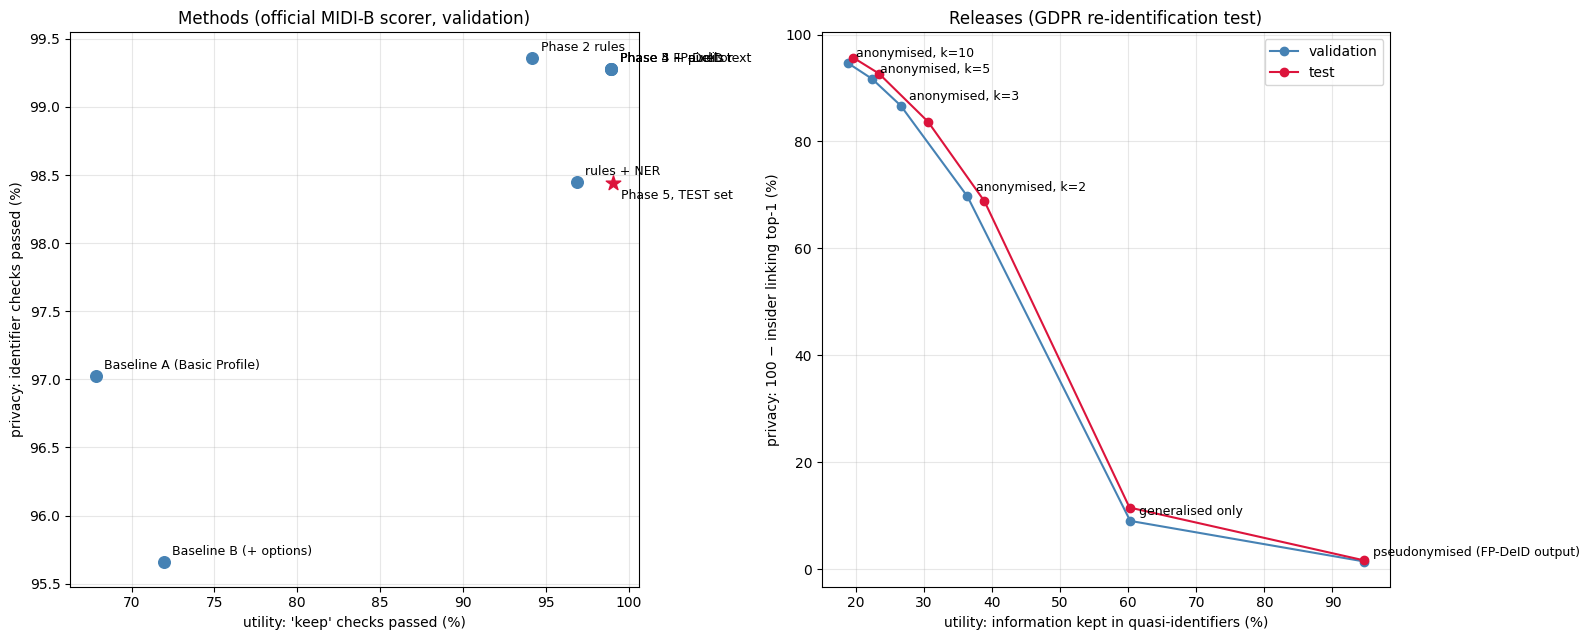

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
ax = axes[0]
for _, point in method_points.iterrows():
    is_test = "TEST" in point["method"]
    ax.scatter(point["utility %"], point["privacy %"], s=120 if is_test else 70,
               marker="*" if is_test else "o", color="crimson" if is_test else "steelblue", zorder=3)
    ax.annotate(point["method"], (point["utility %"], point["privacy %"]), textcoords="offset points",
                xytext=(6, -12 if is_test else 5), fontsize=9)
ax.set_xlabel("utility: 'keep' checks passed (%)")
ax.set_ylabel("privacy: identifier checks passed (%)")
ax.set_title("Methods (official MIDI-B scorer, validation)")
ax.grid(alpha=0.3)

ax = axes[1]
for split, table, color in [("validation", validation_reid, "steelblue"), ("test", test_reid, "crimson")]:
    x = table["QI information kept %"]
    y = 100 - table["link top-1 % (insider)"]
    ax.plot(x, y, marker="o", color=color, label=split)
    if split == "validation":
        for name, xi, yi in zip(table.index, x, y):
            ax.annotate(name, (xi, yi), textcoords="offset points", xytext=(6, 4), fontsize=9)
ax.set_xlabel("utility: information kept in quasi-identifiers (%)")
ax.set_ylabel("privacy: 100 − insider linking top-1 (%)")
ax.set_title("Releases (GDPR re-identification test)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(phase_results, "privacy_utility.png"), dpi=110)
plt.show()

## 6. Ablation table (validation, official scorer), and the test run

In [31]:
ablation_rows = []
ablation_rows.append(["Baseline A: PS3.15 Basic Profile", phase1.loc["weighted_score_%", "BA"],
                      phase1.loc["hipaa_accuracy_%", "BA"], phase1.loc["privacy_failed", "BA"],
                      phase1.loc["utility_failed", "BA"]])
ablation_rows.append(["Baseline B: + options (dates, clean descriptors)", phase1.loc["weighted_score_%", "BB"],
                      phase1.loc["hipaa_accuracy_%", "BB"], phase1.loc["privacy_failed", "BB"],
                      phase1.loc["utility_failed", "BB"]])
ablation_rows.append(["Phase 2: policy engine", phase2.loc["weighted_score_%", "Phase 2"],
                      phase2.loc["hipaa_accuracy_%", "Phase 2"], phase2.loc["privacy_failed", "Phase 2"],
                      phase2.loc["utility_failed", "Phase 2"]])
for name in phase3.index[1:6]:
    ablation_rows.append(["Phase 3: " + name[2:], phase3.loc[name, "weighted_score_%"],
                          phase3.loc[name, "hipaa_accuracy_%"], phase3.loc[name, "privacy_failed"],
                          phase3.loc[name, "utility_failed"]])
ablation_rows.append(["Phase 4: + pixel OCR, value-aware", phase4.loc["weighted_score_%", "Phase 4"],
                      phase4.loc["hipaa_accuracy_%", "Phase 4"], phase4.loc["privacy_failed", "Phase 4"],
                      phase4.loc["utility_failed", "Phase 4"]])
ablation_rows.append(["Phase 5: + closed-loop auditor", validation_score["weighted_score_%"],
                      validation_score["hipaa_accuracy_%"], validation_score["privacy_failed"],
                      validation_score["utility_failed"]])
ablation_rows.append(["TEST SET (once): full FP-DeID", test_score["weighted_score_%"],
                      test_score["hipaa_accuracy_%"], test_score["privacy_failed"], test_score["utility_failed"]])
ablation = pd.DataFrame(ablation_rows, columns=["configuration", "weighted score %", "HIPAA %",
                                                "privacy checks failed", "utility checks failed"])
ablation.to_csv(os.path.join(phase_results, "ablation_all_phases.csv"), index=False)
ablation

,configuration,weighted score %,HIPAA %,privacy checks failed,utility checks failed
0,Baseline A: PS3.15 Basic Profile,95.311,99.989,21358.0,1670457.0
1,"Baseline B: + options (dates, clean descriptors)",95.870,99.988,31131.0,1458139.0
2,Phase 2: policy engine,99.150,99.994,4577.0,302210.0
3,Phase 3: rules + generic patterns,97.406,96.534,25428.0,54997.0
4,Phase 3: rules + NER + patterns,98.799,98.948,11119.0,163270.0
5,Phase 3: rules + fingerprint (exact values),96.651,95.520,47854.0,54999.0
6,"Phase 3: rules + fingerprint (variants, no patterns)",99.077,98.953,19764.0,54999.0
7,Phase 3: FP-DeID (fingerprint + patterns + guard),99.828,99.992,5198.0,55003.0
8,"Phase 4: + pixel OCR, value-aware",99.831,99.996,5177.0,55004.0
9,Phase 5: + closed-loop auditor,99.831,99.996,5177.0,55004.0


## 7. Phase 5 summary vs. pass criteria

In [32]:
header_plants = plant_table[plant_table["where"] == "header"]
pixel_plants = plant_table[plant_table["where"] == "pixels"]
pseudo = test_reid.loc["pseudonymised (FP-DeID output)"]
anon5 = test_reid.loc["anonymised, k=5"]
year_row = test_inference[(test_inference["release"] == "pseudonymised") &
                          (test_inference["hidden fact"] == "study year")].iloc[0]
criteria = pd.DataFrame([
    ["MIDI-B weighted score, TEST set", "≥ 99%", test_score["weighted_score_%"]],
    ["MIDI-B weighted score, validation (same rules)", "= Phase 4 or better", validation_score["weighted_score_%"]],
    ["text leaks on the test set (scorer)", "0, or each listed", len(test_leaks)],
    ["burned-in text checks passed (test)", "all, or each listed",
     str(int(pixel_checks["check_passed"].fillna(0).sum())) + " / " + str(len(pixel_checks))],
    ["auditor: planted header leaks found", "100%",
     str(int(header_plants["found"].sum())) + " / " + str(len(header_plants))],
    ["auditor: planted pixel leaks found", "100%",
     str(int(pixel_plants["found"].sum())) + " / " + str(len(pixel_plants))],
    ["auditor hits per 10,000 elements (validation / test)", "reported",
     str(round(10000 * len(hits_before_fix) / validation_elements, 3)) + " / " +
     str(round(10000 * len(test_auditor_hits) / test_elements, 3))],
    ["auditor hits left after the closed loop (test)", "0", len(test_hits_now)],
    ["singling out, pseudonymised (test): unique %", "reported", pseudo["unique patients %"]],
    ["singling out, anonymised k=5 (test): min k", "≥ 5", anon5["min k"]],
    ["linkability top-1, pseudonymised / anonymised k=5 / random (test)", "reported vs 1/N",
     str(pseudo["link top-1 % (insider)"]) + " / " + str(anon5["link top-1 % (insider)"]) + " / " +
     str(pseudo["random top-1 %"])],
    ["inference of the true study year (test) vs majority guess", "≤ majority",
     str(year_row["attacker accuracy %"]) + " vs " + str(year_row["majority-guess accuracy %"])],
    ["research-field retention (test)", "100%", independent["research fields kept %"]],
    ["DICOM validity (test, all files)", "100%", round(test_valid_pct, 3)],
    ["audit coverage (test)", "100%", independent["audit coverage %"]],
    ["original UIDs left (test)", "0", independent["original UIDs left"]],
], columns=["check", "target", "result"])
criteria.to_csv(os.path.join(phase_results, "pass_criteria.csv"), index=False)
criteria

,check,target,result
0,"MIDI-B weighted score, TEST set",≥ 99%,99.805
1,"MIDI-B weighted score, validation (same rules)",= Phase 4 or better,99.831
2,text leaks on the test set (scorer),"0, or each listed",921
3,burned-in text checks passed (test),"all, or each listed",25 / 27
4,auditor: planted header leaks found,100%,100 / 100
5,auditor: planted pixel leaks found,100%,20 / 20
6,"auditor hits per 10,000 elements (validation / test)",reported,0.0 / 0.082
7,auditor hits left after the closed loop (test),0,0
8,"singling out, pseudonymised (test): unique %",reported,99.4
9,"singling out, anonymised k=5 (test): min k",≥ 5,5.0


## 8. Clean up: keep the audit logs (compressed), delete the large output folders

In [33]:
for split in ["validation", "test"]:
    folder = output_folder(split)
    for name in ["audit.jsonl", "audit_pixels.jsonl", "audit_auditor_fixes.jsonl", "auditor_hits.json", "summary.json"]:
        source_path = os.path.join(folder, name)
        if os.path.exists(source_path):
            with open(source_path, "rb") as source:
                with gzip.open(os.path.join(paths.DERIVED, "phase5_" + split + "_" + name + ".gz"), "wb") as target:
                    shutil.copyfileobj(source, target)
shutil.rmtree(planted_folder, ignore_errors=True)
print("audit logs saved; delete the outputs with DELETE_OUTPUTS = True")
DELETE_OUTPUTS = False
if DELETE_OUTPUTS:
    for split in ["validation", "test"]:
        shutil.rmtree(output_folder(split), ignore_errors=True)

audit logs saved; delete the outputs with DELETE_OUTPUTS = True
